# Yak: continue MLM pretraining from a checkpoint

Loads `ckpt/best.pt` from Drive (model, optimizer and loss-scaler state) and trains further with dropout 0. Run the cells top to bottom.

**Starting point recorded in the checkpoint:** d_model 128, 4 heads, 4 layers, step 24,000, validation loss 4.338, masked accuracy 33.1%.

**How the run is controlled (see the Config cell)**
- `extra_steps` is how many more steps to train. The learning-rate schedule is measured from the step the run starts at (short warm-up to `peak_lr`, cosine decay to `min_lr`), so you never have to edit an absolute `max_steps`.
- `RUN_NAME` identifies the run. If Colab disconnects, re-run all cells with the same `RUN_NAME` and training resumes from `last.pt` and the same schedule. To start a new continuation later, change `RUN_NAME`.
- Before a new run starts, the checkpoint it starts from is copied to `ckpt/<RUN_NAME>_start_step<N>.pt`, so the weights you have now cannot be overwritten.
- `best.pt` is only replaced when validation loss improves, so it always holds your best model.

In [2]:
import os, sys, math, time, json, re, copy, random, shutil
from types import SimpleNamespace
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

In [ ]:


assert torch.cuda.is_available(), "No GPU. Runtime > Change runtime type > GPU, then re-run."
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)

import glob

def setup_storage():
    # Google Drive when the runtime supports it; otherwise local disk.
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        return "/content/drive/MyDrive/yak"
    except Exception as e:
        print(f"Google Drive is not available here ({type(e).__name__}); using local storage instead.")
    base = "/kaggle/working" if os.path.isdir("/kaggle/working") else ("/content" if os.path.isdir("/content") else os.getcwd())
    return os.path.join(base, "yak")

# Your Kaggle dataset files. Each one is copied into <WORK_DIR>/data or <WORK_DIR>/ckpt.
KAGGLE_INPUTS = {
    "/kaggle/input/datasets/gbalachandhiran/wikitext/bpe.json": "data",
    "/kaggle/input/datasets/gbalachandhiran/wikitext/wikitext103_train.txt": "data",
    "/kaggle/input/datasets/gbalachandhiran/best-check-point/best.pt": "ckpt",
    "/kaggle/input/datasets/gbalachandhiran/last-pt/last.pt": "ckpt",
}

def copy_in(src, work_dir, sub):
    dst = os.path.join(work_dir, sub, os.path.basename(src))
    if not os.path.exists(dst):
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        print("copying", src, "->", dst)
        shutil.copy2(src, dst)

def seed_files(work_dir, roots, explicit=None):
    # 1) the exact paths listed above
    for src, sub in (explicit or {}).items():
        if os.path.exists(src):
            copy_in(src, work_dir, sub)
        else:
            print("not found:", src)
    # 2) anything still missing: search the input folders by file name
    wanted = {"bpe.json": "data", "wikitext103_train.txt": "data", "best.pt": "ckpt", "last.pt": "ckpt"}
    for root in roots:
        for dirpath, _, files in os.walk(root):
            if dirpath.startswith(work_dir):
                continue
            for fn in files:
                sub = wanted.get(fn) or ("data" if re.fullmatch(r"(train|val)_\d+_\d+\.npy", fn) else None)
                if sub:
                    copy_in(os.path.join(dirpath, fn), work_dir, sub)

WORK_DIR = setup_storage()
os.makedirs(os.path.join(WORK_DIR, "data"), exist_ok=True)
os.makedirs(os.path.join(WORK_DIR, "ckpt"), exist_ok=True)
if not WORK_DIR.startswith("/content/drive"):
    seed_files(WORK_DIR, [r for r in ("/kaggle/input", "/content") if os.path.isdir(r)], KAGGLE_INPUTS)
print("working directory:", WORK_DIR)
for sub, name in (("data", "bpe.json"), ("data", "wikitext103_train.txt"), ("ckpt", "best.pt"), ("ckpt", "last.pt")):
    p = os.path.join(WORK_DIR, sub, name)
    print(f"  {'OK     ' if os.path.exists(p) else 'MISSING'} {sub}/{name}" + (f"  ({os.path.getsize(p) / 1e6:.1f} MB)" if os.path.exists(p) else ""))

GPU: Tesla T4 | torch 2.11.0+cu128
Google Drive is not available here (NotImplementedError); using local storage instead.
copying /kaggle/input/datasets/gbalachandhiran/wikitext/bpe.json -> /kaggle/working/yak/data/bpe.json
copying /kaggle/input/datasets/gbalachandhiran/wikitext/wikitext103_train.txt -> /kaggle/working/yak/data/wikitext103_train.txt
copying /kaggle/input/datasets/gbalachandhiran/best-check-point/best.pt -> /kaggle/working/yak/ckpt/best.pt
copying /kaggle/input/datasets/gbalachandhiran/last-pt/last.pt -> /kaggle/working/yak/ckpt/last.pt
working directory: /kaggle/working/yak
  OK      data/bpe.json  (1.8 MB)
  OK      data/wikitext103_train.txt  (541.1 MB)
  OK      ckpt/best.pt  (56.1 MB)
  OK      ckpt/last.pt  (56.1 MB)


In [3]:
# Model code: identical to the repo files on feature/mlm, inlined so no imports are needed.
class FFN(nn.Module):
    """Feed Forward Network module
    Args:
        d_model: dimension of the model
        d_ff: dimension of the feed forward network
        dropout: dropout rate
    """
    def __init__(self,d_model:int,dropout:float=0.1,ff_multiplier:int=4):
        super().__init__()
        self.d_model = d_model
        self.d_ff = d_model * ff_multiplier
        self.linear1 = nn.Linear(d_model, self.d_ff)
        self.linear2 = nn.Linear(self.d_ff, d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = nn.GELU()

    def forward(self,x:torch.Tensor) -> torch.Tensor:
        x = self.linear1(x)
        x = self.activation(x)
        x = self.linear2(x)
        x = self.dropout(x)
        return x


class BiDirectionalAttention(nn.Module):
    """Multi head bidirectional self-attention.

    Same interface and maths as before, but uses F.scaled_dot_product_attention so the
    (seq_len x seq_len) score matrix is never fully materialised. That matters at the
    2,048 token context.

    Args:
        d_model: dimension of the model
        nhead: number of heads
        dropout: attention dropout rate
    """

    def __init__(self, d_model: int, nhead: int, dropout: float = 0.1):
        super().__init__()
        assert d_model % nhead == 0, "d_model must be divisible by nhead"
        self.d_model = d_model
        self.nhead = nhead
        self.d_k = d_model // nhead
        self.dropout_p = dropout

        self.qkv_proj = nn.Linear(d_model, d_model * 3)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x: torch.Tensor, padding_mask: torch.Tensor | None = None) -> torch.Tensor:
        """
        Args:
            x: (batch_size, seq_len, d_model)
            padding_mask: optional (batch_size, seq_len), True/1 for real tokens, False/0 for padding
        Returns:
            (batch_size, seq_len, d_model)
        """
        batch_size, seq_len, _ = x.size()
        qkv = self.qkv_proj(x).view(batch_size, seq_len, 3, self.nhead, self.d_k)
        qkv = qkv.permute(2, 0, 3, 1, 4)  # (3, B, nhead, L, d_k)
        q, k, v = qkv[0], qkv[1], qkv[2]

        attn_mask = None
        if padding_mask is not None:
            attn_mask = padding_mask.bool()[:, None, None, :]  # (B, 1, 1, L), True = may attend

        out = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=attn_mask,
            dropout_p=self.dropout_p if self.training else 0.0,
        )  # (B, nhead, L, d_k)
        out = out.transpose(1, 2).reshape(batch_size, seq_len, self.d_model)
        return self.out_proj(out)


class EncoderBlock(nn.Module):
    """Pre norm encoder block with multi head attention and feed forward network
    x = x+attebtion(LayerNorm(x),mask)
    x = x+FFN(LayerNorm(x))

    Args:
        d_model: dimension of the model
        nhead: number of heads
        dropout: dropout rate
    Shape:
        - Input: (batch_size, seq_len, d_model)
        - Output: (batch_size, seq_len, d_model)
    """
    def __init__(self,d_model:int,nhead:int,dropout:float=0.1):
        super().__init__()
        self.d_model = d_model
        self.nhead = nhead
        self.dropout = dropout

        self.attention = BiDirectionalAttention(d_model,nhead,dropout)
        self.ffn = FFN(d_model,dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self,x:torch.Tensor,padding_mask:torch.Tensor| None = None) -> torch.Tensor:
        """Feed forward pass of the encoder block
        Args:
            x: input tensor of shape (batch_size, seq_len, d_model)
            padding_mask: optional mask tensor of shape (batch_size, seq_len)
        Returns:
            output tensor of shape (batch_size, seq_len, d_model)
        """
        # Sub 1: Normalize -> Attention (mask goes here only for the attention) -> Skip connection
        x_norm = self.norm1(x)
        attn_output = self.attention(x_norm,padding_mask)
        x = x + attn_output

        # Sub 2: Normalize -> Feed Forward -> Skip connection
        x_norm = self.norm2(x)
        ffn_output = self.ffn(x_norm)
        x = x + ffn_output
        return x



class EmbedPos(nn.Module):
    """Token embedding + static sinusoidal positions (sin/cos), followed by dropout.

    Token embeddings are initialised with std = d_model ** -0.5 and scaled by
    sqrt(d_model) in forward, so they have unit scale and are not drowned out by the
    +-1 positional signal. The same init keeps the tied output head's starting
    logits small, so the initial loss lands near ln(vocab_size).

    Args:
        vocab_size: number of token ids (len(tok2id), including special tokens)
        d_model: model width (must be even)
        max_len: length of the sinusoidal table
        pad_id: id of the padding token
        dropout: dropout rate applied to the summed embedding
    """

    def __init__(self, vocab_size, d_model=256, max_len=2048, pad_id=0, dropout=0.1):
        super().__init__()
        assert d_model % 2 == 0, "d_model must be even for sin/cos pairs"
        self.vocab_size = vocab_size
        self.d_model = d_model
        self.max_len = max_len
        self.pad_id = pad_id
        self.dropout = nn.Dropout(dropout)
        self.tok_emb = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        nn.init.normal_(self.tok_emb.weight, mean=0.0, std=d_model ** -0.5)
        with torch.no_grad():
            self.tok_emb.weight[pad_id].zero_()
        # Fixed table: moves with .to(device), is not a parameter, and is not saved in checkpoints.
        self.register_buffer(
            "pos_emb", self._get_positional_encoding(max_len, d_model), persistent=False
        )

    @staticmethod
    def _get_positional_encoding(max_len, d_model):
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        return pe.unsqueeze(0)  # (1, max_len, d_model)

    def forward(self, ids):
        # ids: (batch_size, seq_len)
        seq_len = ids.size(1)
        if seq_len > self.max_len:
            raise ValueError(f"seq_len {seq_len} exceeds max_len {self.max_len}")
        tok_emb = self.tok_emb(ids) * math.sqrt(self.d_model)  # (B, L, d_model)
        emb = tok_emb + self.pos_emb[:, :seq_len, :].to(tok_emb.dtype)
        return self.dropout(emb)


class MlmModel(nn.Module):
    """Masked language model, phase 1 pre-training.

    ids -> EmbedPos -> N x EncoderBlock (pre-norm) -> final LayerNorm -> tied MLM head -> logits

    The head shares its weight with the token embedding, plus a separate output bias.

    Args:
        vocab_size: number of token ids, INCLUDING special tokens (len(tokenizer.tok2id))
        d_model: model width
        nhead: attention heads
        num_layers: number of encoder blocks
        max_seq_len: length of the sinusoidal positional table
        dropout: dropout rate
        pad_token_id: id of the padding token
    """

    def __init__(self, vocab_size: int, d_model: int, nhead: int, num_layers: int,
                 max_seq_len: int, dropout: float = 0.1, pad_token_id: int = 0):
        super().__init__()
        self.pad_id = pad_token_id
        self.vocab_size = vocab_size
        self.d_model = d_model

        self.embed = EmbedPos(vocab_size, d_model=d_model, max_len=max_seq_len,
                              pad_id=pad_token_id, dropout=dropout)
        self.blocks = nn.ModuleList(
            [EncoderBlock(d_model, nhead, dropout) for _ in range(num_layers)]
        )
        # Blocks are pre-norm, so the last residual stream must be normalised before the head.
        self.final_norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head_bias = nn.Parameter(torch.zeros(vocab_size))

        self.apply(self._init_weights)
        # GPT-2 style: shrink the init of the two residual output projections per block.
        for name, p in self.named_parameters():
            if name.endswith("out_proj.weight") or name.endswith("linear2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * num_layers))

        emb_weight = self.embed.tok_emb.weight
        assert emb_weight.shape == (vocab_size, d_model), (
            f"Embedding weight shape {tuple(emb_weight.shape)} != {(vocab_size, d_model)}"
        )
        self.head.weight = emb_weight  # tie head to the token embedding

    def _init_weights(self, m):
        # The head is skipped: it is tied to the embedding, which EmbedPos already initialised.
        if isinstance(m, nn.Linear) and m is not self.head:
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def num_parameters(self, exclude_embedding: bool = False) -> int:
        n = sum(p.numel() for p in self.parameters())  # tied weight is counted once
        if exclude_embedding:
            n -= self.embed.tok_emb.weight.numel()
        return n

    def encode(self, ids: torch.Tensor) -> torch.Tensor:
        """(batch, seq_len) ids -> (batch, seq_len, d_model) hidden states."""
        keep = ids != self.pad_id  # True for real tokens
        # Fully packed batches have no padding; skipping the mask enables the fastest attention kernels.
        padding_mask = None if bool(keep.all()) else keep
        x = self.embed(ids)
        for block in self.blocks:
            x = block(x, padding_mask)
        return self.final_norm(x)

    def _logits(self, h: torch.Tensor) -> torch.Tensor:
        return F.linear(h, self.head.weight, self.head_bias)

    def forward(self, ids: torch.Tensor, labels: torch.Tensor | None = None):
        """
        labels is None -> full logits (batch, seq_len, vocab_size), for inference.
        labels given   -> (loss, logits_at_selected_positions, targets). Only positions with
                          labels != -100 go through the vocabulary projection, which saves a
                          lot of memory (about 15% of positions instead of all of them).
        """
        h = self.encode(ids)
        if labels is None:
            return self._logits(h)
        sel = labels != -100
        targets = labels[sel]
        if targets.numel() == 0:
            return h.sum() * 0.0, None, targets
        logits = self._logits(h[sel])  # (n_selected, vocab_size)
        loss = F.cross_entropy(logits.float(), targets)
        return loss, logits, targets

In [4]:
CFG = dict(
    # architecture: a checkpoint must match this (checked when it loads)
    d_model=128, nhead=4, num_layers=4, dropout=0.0, max_seq_len=2048,
    # batching: tokens per step = micro_bs * seq_len * accum
    seq_len=2048, micro_bs=64, accum=1,
    mask_prob=0.15,          # masking rate used for TRAINING
    eval_mask_prob=0.15,     # masking rate used for VALIDATION; keep fixed so numbers stay comparable across runs
    # schedule when NO checkpoint exists (training from scratch)
    scratch_steps=24000, scratch_warmup_steps=500, scratch_peak_lr=6e-4, scratch_min_lr=6e-5,
    # schedule when CONTINUING a checkpoint, measured from the step the run starts at
    extra_steps=12000, warmup_steps=200, peak_lr=3e-4, min_lr=3e-5,
    weight_decay=0.01, betas=(0.9, 0.98), grad_clip=1.0,
    # bookkeeping
    log_every=50, eval_every=500, ckpt_every=500, eval_seqs=256,
    seed=1337,
)
RUN_NAME   = "run1"          # keep it the same to resume after a disconnect; change it to start a new run
START_FROM = "best"          # a NEW continuation starts from "best" (best.pt) or "last" (last.pt)
ALLOW_SCRATCH = False        # False: stop with an error if no checkpoint is found. True: train from scratch in that case.

In [5]:
BPE_PATH  = os.path.join(WORK_DIR, "data", "bpe.json")
TRAIN_TXT = os.path.join(WORK_DIR, "data", "wikitext103_train.txt")
assert os.path.exists(BPE_PATH), f"missing tokenizer file: {BPE_PATH}"

with open(BPE_PATH, "r", encoding="utf-8") as f:
    _raw = json.load(f)
bpe = SimpleNamespace(
    tok2id=_raw["tok2id"],
    special_tokens=_raw["special_tokens"],
    merges=[tuple(p) for p in _raw["merges"]],
)
bpe.id2tok = {i: t for t, i in bpe.tok2id.items()}

VOCAB_SIZE = len(bpe.tok2id)                       # 30,000 entries + 5 special tokens
PAD, UNK, CLS, SEP, MASK = (bpe.tok2id[t] for t in ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"])
N_SPECIAL = len(bpe.special_tokens)


class FastBPE:
    # Same result as BPE.encode_word, but applies the lowest-ranked merge present
    # instead of running every merge regex over every word, and caches per word.
    def __init__(self, bpe):
        self.rank = {tuple(p): i for i, p in enumerate(bpe.merges)}
        self.tok2id = bpe.tok2id
        self.unk = bpe.tok2id["[UNK]"]
        self.cache = {}

    def _encode(self, word):
        symbols = list(word) + ["</w>"]
        rank = self.rank
        while len(symbols) > 1:
            best, best_rank = None, None
            for i in range(len(symbols) - 1):
                r = rank.get((symbols[i], symbols[i + 1]))
                if r is not None and (best_rank is None or r < best_rank):
                    best, best_rank = (symbols[i], symbols[i + 1]), r
            if best is None:
                break
            merged, i = [], 0
            while i < len(symbols):
                if i < len(symbols) - 1 and symbols[i] == best[0] and symbols[i + 1] == best[1]:
                    merged.append(best[0] + best[1]); i += 2
                else:
                    merged.append(symbols[i]); i += 1
            symbols = merged
        return tuple(self.tok2id.get(s, self.unk) for s in symbols)

    def line_ids(self, line):
        out, cache = [], self.cache
        for w in line.split():
            t = cache.get(w)
            if t is None:
                t = cache[w] = self._encode(w)
            out.extend(t)
        return out






fast = FastBPE(bpe)
print(f"vocab size {VOCAB_SIZE} | merges {len(bpe.merges)}")

vocab size 30005 | merges 25022


In [14]:
# Tokenized data: loads the cache written earlier on Drive; only builds it if it is missing.
from array import array
from tqdm.auto import tqdm

DATA_DIR = os.path.join(WORK_DIR, "data")
if os.path.exists(TRAIN_TXT):
    TAG = f"{os.path.getsize(TRAIN_TXT)}_{os.path.getsize(BPE_PATH)}"      # sizes in the name guard against stale caches
    TRAIN_NPY = os.path.join(DATA_DIR, f"train_{TAG}.npy")
    VAL_NPY   = os.path.join(DATA_DIR, f"val_{TAG}.npy")
else:
    found = sorted(glob.glob(os.path.join(DATA_DIR, "train_*.npy")))
    assert found, f"need wikitext103_train.txt or the cached train_*.npy and val_*.npy files in {DATA_DIR}"
    TRAIN_NPY = found[-1]
    VAL_NPY = os.path.join(DATA_DIR, os.path.basename(TRAIN_NPY).replace("train_", "val_", 1))

if not (os.path.exists(TRAIN_NPY) and os.path.exists(VAL_NPY)):
    assert os.path.exists(TRAIN_TXT), f"no cached ids and no training text at {TRAIN_TXT}"
    print("no cached ids found; tokenizing (one-off, several minutes)")
    ARTICLE_RE = re.compile(r"^ = [^=].* = \n?$")
    HOLDOUT_EVERY = 200                              # every 200th article (about 0.5%) -> validation
    streams, last_doc, art = {"train": array("H"), "val": array("H")}, {"train": None, "val": None}, 0
    with open(TRAIN_TXT, "r", encoding="utf-8") as f:
        for line in tqdm(f, unit="line"):
            if not line.strip():
                continue
            if ARTICLE_RE.match(line):
                art += 1
            name = "val" if art % HOLDOUT_EVERY == HOLDOUT_EVERY - 1 else "train"
            if last_doc[name] is not None and last_doc[name] != art:
                streams[name].append(SEP)
            last_doc[name] = art
            streams[name].extend(fast.line_ids(line))
    np.save(VAL_NPY, np.frombuffer(streams["val"], dtype=np.uint16))
    np.save(TRAIN_NPY, np.frombuffer(streams["train"], dtype=np.uint16))

train_ids = np.load(TRAIN_NPY)
val_ids = np.load(VAL_NPY)
print(f"train tokens: {len(train_ids):,} | val tokens: {len(val_ids):,}")

no cached ids found; tokenizing (one-off, several minutes)


0line [00:00, ?line/s]

train tokens: 114,070,037 | val tokens: 537,887


In [9]:
device = "cuda"

def sample_batch(data, bs, L, rng):
    # Random windows of L-1 tokens from the stream, with [CLS] prepended.
    starts = rng.integers(0, len(data) - (L - 1), size=bs)
    idx = starts[:, None] + np.arange(L - 1)[None, :]
    body = torch.from_numpy(data[idx].astype(np.int64))
    return torch.cat([torch.full((bs, 1), CLS, dtype=torch.long), body], dim=1)

def val_chunks(data, L, max_seqs=None):
    n = len(data) // (L - 1)
    body = torch.from_numpy(data[: n * (L - 1)].astype(np.int64)).view(n, L - 1)
    chunks = torch.cat([torch.full((n, 1), CLS, dtype=torch.long), body], dim=1)
    return chunks[:max_seqs] if max_seqs else chunks

def mask_tokens(ids, p=0.15, gen=None):
    # Dynamic MLM masking: pick 15% of non-special tokens; of those 80% -> [MASK], 10% -> random token, 10% unchanged.
    dev = ids.device
    sel = (torch.rand(ids.shape, device=dev, generator=gen) < p) & (ids >= N_SPECIAL)
    labels = ids.clone()
    labels[~sel] = -100
    r = torch.rand(ids.shape, device=dev, generator=gen)
    inp = ids.clone()
    inp[sel & (r < 0.8)] = MASK
    rand_pos = sel & (r >= 0.8) & (r < 0.9)
    random_tok = torch.randint(N_SPECIAL, VOCAB_SIZE, ids.shape, device=dev, generator=gen)
    inp[rand_pos] = random_tok[rand_pos]
    return inp, labels

# Baseline to beat: always predict the single most frequent non-special token.
counts = np.bincount(val_ids, minlength=VOCAB_SIZE)
top_tok = int(counts[N_SPECIAL:].argmax()) + N_SPECIAL
BASELINE_ACC = counts[top_tok] / counts[N_SPECIAL:].sum()
print(f"frequency baseline: always predict {bpe.id2tok[top_tok]!r} -> {BASELINE_ACC:.2%} masked accuracy")

NameError: name 'val_ids' is not defined

In [14]:
!date

Tue Oct 20 09:56:20 AM UTC 2026


total 1423668
-rw-r--r-- 1 root root 56067359 Oct 20 12:17 last.pt
-rw-r--r-- 1 root root       53 Oct 20 12:17 best.pt_20261020_121734.txt
-rw-r--r-- 1 root root 56071359 Oct 20 12:17 best.pt_20261020_121734
-rw-r--r-- 1 root root       53 Oct 20 12:12 best.pt_20261020_121221.txt
-rw-r--r-- 1 root root 56070911 Oct 20 12:12 best.pt_20261020_121221
-rw-r--r-- 1 root root       53 Oct 20 12:07 best.pt_20261020_120708.txt
-rw-r--r-- 1 root root 56070399 Oct 20 12:07 best.pt_20261020_120708
-rw-r--r-- 1 root root       53 Oct 20 11:56 best.pt_20261020_115642.txt
-rw-r--r-- 1 root root 56069439 Oct 20 11:56 best.pt_20261020_115642


In [17]:
!ls -lt /kaggle/input/datasets/gbalachandhiran/best-check-point | head -n 5

total 54742
-rw-rw-rw- 1 root root 56054943 Oct 20 07:19 best.pt


In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"
def build_model():
    return MlmModel(vocab_size=30005, d_model=CFG["d_model"], nhead=CFG["nhead"],
                    num_layers=CFG["num_layers"], max_seq_len=CFG["max_seq_len"],
                    dropout=CFG["dropout"], pad_token_id=0).to(device)

model = build_model()

In [9]:
print(model)

MlmModel(
  (embed): EmbedPos(
    (dropout): Dropout(p=0.0, inplace=False)
    (tok_emb): Embedding(30005, 128, padding_idx=0)
  )
  (blocks): ModuleList(
    (0-3): 4 x EncoderBlock(
      (attention): BiDirectionalAttention(
        (qkv_proj): Linear(in_features=128, out_features=384, bias=True)
        (out_proj): Linear(in_features=128, out_features=128, bias=True)
      )
      (ffn): FFN(
        (linear1): Linear(in_features=128, out_features=512, bias=True)
        (linear2): Linear(in_features=512, out_features=128, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (activation): GELU(approximate='none')
      )
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
    )
  )
  (final_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=128, out_features=30005, bias=False)
)


In [ ]:
device = "cuda"
use_bf16 = torch.cuda.get_device_capability()[0] >= 8       # T4 has no bf16: it uses fp16 with loss scaling
amp_dtype = torch.bfloat16 if use_bf16 else torch.float16
scaler = torch.amp.GradScaler("cuda", enabled=not use_bf16)

L, accum = CFG["seq_len"], CFG["accum"]
tokens_per_step = CFG["micro_bs"] * L * accum
print(f"precision {amp_dtype} | {CFG['micro_bs']} x {L} x accum {accum} = {tokens_per_step:,} tokens/step")

def build_model():
    return MlmModel(vocab_size=30005, d_model=CFG["d_model"], nhead=CFG["nhead"],
                    num_layers=CFG["num_layers"], max_seq_len=CFG["max_seq_len"],
                    dropout=CFG["dropout"], pad_token_id=PAD).to(device)

model = build_model()
n_total = model.num_parameters()
n_emb = model.embed.tok_emb.weight.numel()
print(f"parameters: {n_total / 1e6:.2f}M total = {n_emb / 1e6:.2f}M embedding (shared with the output head) + {(n_total - n_emb) / 1e6:.2f}M transformer")

decay, no_decay = [], []
for name, p in model.named_parameters():
    (decay if (p.dim() >= 2 and "tok_emb" not in name) else no_decay).append(p)
opt = torch.optim.AdamW(
    [{"params": decay, "weight_decay": CFG["weight_decay"]}, {"params": no_decay, "weight_decay": 0.0}],
    lr=CFG["peak_lr"], betas=CFG["betas"], fused=True,
)

VAL = val_chunks(val_ids, L, max_seqs=CFG["eval_seqs"])

@torch.no_grad()
def evaluate(m, chunks, bs):
    m.eval()
    g = torch.Generator(device=device); g.manual_seed(0)      # same masks every time -> comparable numbers
    tl = tc = tn = 0
    for i in range(0, len(chunks), bs):
        ids = chunks[i:i + bs].to(device)
        inp, lab = mask_tokens(ids, CFG["eval_mask_prob"], g)
        with torch.autocast("cuda", dtype=amp_dtype):
            loss, logits, targets = m(inp, lab)
        k = targets.numel()
        tl += loss.item() * k; tc += (logits.argmax(-1) == targets).sum().item(); tn += k
    m.train()
    return tl / tn, tc / tn

CKPT_DIR = os.path.join("/kaggle/working/yak", "ckpt"); os.makedirs(CKPT_DIR, exist_ok=True)
LAST, BEST = os.path.join(CKPT_DIR, "last.pt"), os.path.join(CKPT_DIR, "best.pt")

def save_ckpt(path, step, best_val, history):
    tmp = path + ".tmp"
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                "step": step, "best_val": best_val, "history": history, "cfg": CFG,
                "vocab_size": VOCAB_SIZE, "run": {"name": RUN_NAME, "base_step": base_step, "mode": mode}}, tmp)
    os.replace(tmp, path)           # atomic: a disconnect cannot leave a half-written file

def plan_run(last_ckpt_run, run_name):
    """Returns (base_step, resuming). last.pt written by the same run means: continue that run's schedule."""
    if last_ckpt_run and last_ckpt_run.get("name") == run_name:
        return last_ckpt_run["base_step"], True
    return None, False

def lr_at(step):
    s = step - base_step                          # schedule is relative to where this run started
    lo, hi, w, T = SCHED["lo"], SCHED["hi"], SCHED["warmup"], SCHED["steps"]
    if s < w:
        return SCHED["start"] + (hi - SCHED["start"]) * (s + 1) / w     # scratch warms up from 0; a continuation from its floor
    prog = min(1.0, (s - w) / max(1, T - w))
    return lo + 0.5 * (hi - lo) * (1 + math.cos(math.pi * prog))

# ---- decide what to do: resume this run, continue a checkpoint, or train from scratch ----
have_ckpt = os.path.exists(BEST) or os.path.exists(LAST)
last_run = torch.load(LAST, map_location="cpu").get("run") if os.path.exists(LAST) else None
base_step, resuming = plan_run(last_run, RUN_NAME)
if resuming:
    mode, load_path = last_run.get("mode", "continue"), LAST
elif have_ckpt:
    mode = "continue"
    load_path = LAST if START_FROM == "last" else BEST
    if not os.path.exists(load_path):
        load_path = LAST if os.path.exists(LAST) else BEST
else:
    if not ALLOW_SCRATCH:
        found = sorted(glob.glob(os.path.join(WORK_DIR, "**", "*.pt"), recursive=True))
        raise FileNotFoundError(
            f"No checkpoint found at {BEST} or {LAST}. Upload best.pt (and last.pt) so they end up in {CKPT_DIR}, "
            f"or set ALLOW_SCRATCH = True in the Config cell to train from scratch. .pt files under {WORK_DIR}: {found or 'none'}")
    mode, load_path = "scratch", None

if mode == "scratch":
    SCHED = dict(steps=CFG["scratch_steps"], warmup=CFG["scratch_warmup_steps"], hi=CFG["scratch_peak_lr"], lo=CFG["scratch_min_lr"], start=0.0)
else:
    SCHED = dict(steps=CFG["extra_steps"], warmup=CFG["warmup_steps"], hi=CFG["peak_lr"], lo=CFG["min_lr"], start=CFG["min_lr"])

if load_path:
    ck = torch.load(load_path, map_location=device)
    saved = ck["cfg"]
    for k in ("d_model", "nhead", "num_layers", "max_seq_len"):
        assert saved[k] == CFG[k], f"checkpoint was trained with {k}={saved[k]}, but CFG has {k}={CFG[k]}"
    assert ck["vocab_size"] == VOCAB_SIZE, f"checkpoint vocab {ck['vocab_size']} != tokenizer vocab {VOCAB_SIZE}"
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
    start_step, best_val, history = ck["step"], ck["best_val"], ck["history"]
    if not resuming:
        base_step = start_step
        backup = os.path.join(CKPT_DIR, f"{RUN_NAME}_start_step{start_step}.pt")
        if not os.path.exists(backup):
            shutil.copy2(load_path, backup)
            print("backup of the starting checkpoint:", backup)
else:
    start_step, best_val, history, base_step = 0, float("inf"), [], 0
END_STEP = base_step + SCHED["steps"]
label = "RESUMING" if resuming else ("NEW RUN, continuing a checkpoint" if load_path else "NEW RUN, training from scratch")
print(f"{label} '{RUN_NAME}' | step {start_step} -> {END_STEP} | peak lr {SCHED['hi']:.1e}, warm-up {SCHED['warmup']} steps, floor {SCHED['lo']:.1e}")
if start_step >= END_STEP:
    print("This run is already complete. Change RUN_NAME (and extra_steps if you like) to start another continuation.")

# ---- starting-point check ----
vl, va = evaluate(model, VAL, CFG["micro_bs"])
counts = np.bincount(val_ids, minlength=VOCAB_SIZE)
BASELINE_ACC = counts[N_SPECIAL:].max() / counts[N_SPECIAL:].sum()
if load_path is None:
    print(f"untrained model: val loss {vl:.3f} (ln of vocab size = {math.log(VOCAB_SIZE):.3f}) | frequency baseline {BASELINE_ACC:.2%}")
    assert abs(vl - math.log(VOCAB_SIZE)) < 1.0, "untrained loss is far from ln(V); check the model code and the data"
else:
    print(f"loaded weights: val loss {vl:.4f} | masked acc {va:.2%} (frequency baseline {BASELINE_ACC:.2%})")
    if os.path.basename(load_path) == "best.pt":
        assert abs(vl - ck["best_val"]) < 5e-3, "loaded weights do not reproduce the stored validation loss; check CFG and the data cache"

precision torch.float16 | 64 x 2048 x accum 1 = 131,072 tokens/step
parameters: 4.66M total = 3.84M embedding (shared with the output head) + 0.82M transformer
backup of the starting checkpoint: /kaggle/working/yak/ckpt/run1_start_step24000.pt
NEW RUN, continuing a checkpoint 'run1' | step 24000 -> 36000 | peak lr 3.0e-04, warm-up 200 steps, floor 3.0e-05
loaded weights: val loss 4.3381 | masked acc 33.13% (frequency baseline 4.77%)


In [ ]:
model.train()
t_start, tok_seen, done = time.time(), 0, start_step
run_loss = torch.zeros((), device=device)
try:
    for step in range(start_step, END_STEP):
        lr_now = lr_at(step)
        for g in opt.param_groups:
            g["lr"] = lr_now

        for micro in range(accum):
            rng = np.random.default_rng([CFG["seed"], step, micro])     # deterministic per step -> exact resume
            ids = sample_batch(train_ids, CFG["micro_bs"], L, rng).to(device, non_blocking=True)
            inp, lab = mask_tokens(ids, CFG["mask_prob"])
            with torch.autocast("cuda", dtype=amp_dtype):
                loss, _, _ = model(inp, lab)
            scaler.scale(loss / accum).backward()
            run_loss += loss.detach() / accum
        scaler.unscale_(opt)
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        tok_seen += tokens_per_step
        done = step + 1

        if done % CFG["log_every"] == 0:
            avg = run_loss.item() / CFG["log_every"]; run_loss.zero_()
            if not math.isfinite(avg):
                raise RuntimeError(f"loss is {avg} at step {done}; lower peak_lr or resume from an earlier checkpoint")
            el = time.time() - t_start
            eta = (END_STEP - done) * el / max(1, done - start_step)
            history.append({"step": done, "train_loss": avg, "lr": lr_now})
            print(f"step {done:6d}/{END_STEP} | loss {avg:.4f} | lr {lr_now:.2e} | gnorm {float(gnorm):.2f} "
                  f"| {tok_seen / el / 1e3:.0f}k tok/s | ETA {eta / 60:.0f} min")

        if done % CFG["eval_every"] == 0 or done == END_STEP:
            vl, va = evaluate(model, VAL, CFG["micro_bs"])
            history.append({"step": done, "val_loss": vl, "val_acc": va})
            flag = ""
            if vl < best_val:
                best_val = vl; save_ckpt(BEST, done, best_val, history); flag = "  (new best)"
            print(f"  VAL step {done}: loss {vl:.4f} | masked acc {va:.2%} (baseline {BASELINE_ACC:.2%}){flag}")

        if done % CFG["ckpt_every"] == 0 or done == END_STEP:
            save_ckpt(LAST, done, best_val, history)
except KeyboardInterrupt:
    save_ckpt(LAST, done, best_val, history)
    print(f"stopped by you at step {done}; saved last.pt. Re-run all cells with the same RUN_NAME to resume.")
else:
    print("run finished")

In [22]:
import time
from datetime import datetime
best_val_acc = 0.33
# --- Make sure to initialize best_val_acc somewhere before the loop ---
# best_val_acc = 0.0  # Initialize to 0 before starting the training loop

model.train()
t_start, tok_seen, done = time.time(), 0, start_step
run_loss = torch.zeros((), device=device)
try:
    for step in range(start_step, END_STEP):
        lr_now = lr_at(step)
        for g in opt.param_groups:
            g["lr"] = lr_now

        for micro in range(accum):
            rng = np.random.default_rng([CFG["seed"], step, micro])     # deterministic per step -> exact resume
            ids = sample_batch(train_ids, CFG["micro_bs"], L, rng).to(device, non_blocking=True)
            inp, lab = mask_tokens(ids, CFG["mask_prob"])
            with torch.autocast("cuda", dtype=amp_dtype):
                loss, _, _ = model(inp, lab)
            scaler.scale(loss / accum).backward()
            run_loss += loss.detach() / accum
        scaler.unscale_(opt)
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        tok_seen += tokens_per_step
        done = step + 1

        if done % CFG["log_every"] == 0:
            avg = run_loss.item() / CFG["log_every"]; run_loss.zero_()
            if not math.isfinite(avg):
                raise RuntimeError(f"loss is {avg} at step {done}; lower peak_lr or resume from an earlier checkpoint")
            el = time.time() - t_start
            eta = (END_STEP - done) * el / max(1, done - start_step)
            history.append({"step": done, "train_loss": avg, "lr": lr_now})
            print(f"step {done:6d}/{END_STEP} | loss {avg:.4f} | lr {lr_now:.2e} | gnorm {float(gnorm):.2f} "
                  f"| {tok_seen / el / 1e3:.0f}k tok/s | ETA {eta / 60:.0f} min")

        if done % CFG["eval_every"] == 0 or done == END_STEP:
            vl, va = evaluate(model, VAL, CFG["micro_bs"])
            history.append({"step": done, "val_loss": vl, "val_acc": va})
            flag = ""
            
            # Track highest validation accuracy instead of lowest loss
            if va > best_val_acc:
                best_val_acc = va
                flag = "  (new best acc)"
                
                # Generate a clean timestamp (e.g., 20261020_153022)
                timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
                
                # Create a dynamic filename base incorporating the timestamp
                # Example output base: "best_model_20261020_153022"
                timestamped_filename = f"{BEST}_{timestamp}" 
                
                # 1. Save the model checkpoint with the timestamped name
                save_ckpt(timestamped_filename, done, best_val_acc, history)
                
                # 2. Write the text file containing your metrics with the exact same name base
                txt_filename = f"{timestamped_filename}.txt"
                with open(txt_filename, "w") as f:
                    f.write(f"latest_val_acc: {best_val_acc:.4f}\n")
                    f.write(f"loss: {vl:.4f}\n")
                    f.write(f"accuracy: {va:.4f}\n")
                
            print(f"  VAL step {done}: loss {vl:.4f} | masked acc {va:.2%} (baseline {BASELINE_ACC:.2%}){flag}")

        if done % CFG["ckpt_every"] == 0 or done == END_STEP:
            save_ckpt(LAST, done, best_val_acc, history)
            
except KeyboardInterrupt:
    save_ckpt(LAST, done, best_val_acc, history)
    print(f"stopped by you at step {done}; saved last.pt. Re-run all cells with the same RUN_NAME to resume.")
else:
    print("run finished")


step  24050/36000 | loss 4.2743 | lr 9.75e-05 | gnorm 1.12 | 215k tok/s | ETA 121 min
step  24100/36000 | loss 4.2660 | lr 1.65e-04 | gnorm 1.26 | 211k tok/s | ETA 123 min
step  24150/36000 | loss 4.2463 | lr 2.32e-04 | gnorm 1.21 | 211k tok/s | ETA 123 min
step  24200/36000 | loss 4.2688 | lr 3.00e-04 | gnorm 1.43 | 211k tok/s | ETA 122 min
step  24250/36000 | loss 4.2452 | lr 3.00e-04 | gnorm 1.28 | 210k tok/s | ETA 122 min
step  24300/36000 | loss 4.2442 | lr 3.00e-04 | gnorm 1.48 | 210k tok/s | ETA 121 min
step  24350/36000 | loss 4.2219 | lr 3.00e-04 | gnorm 1.53 | 210k tok/s | ETA 121 min
step  24400/36000 | loss 4.2076 | lr 3.00e-04 | gnorm 1.57 | 210k tok/s | ETA 121 min
step  24450/36000 | loss 4.2095 | lr 3.00e-04 | gnorm 1.46 | 210k tok/s | ETA 120 min
step  24500/36000 | loss 4.1891 | lr 3.00e-04 | gnorm 1.17 | 210k tok/s | ETA 120 min
  VAL step 24500: loss 4.1891 | masked acc 34.84% (baseline 4.77%)  (new best acc)
step  24550/36000 | loss 4.1923 | lr 2.99e-04 | gnorm 1.2

best.pt (step 32000): full-validation loss 3.4549 | masked acc 42.89% | frequency baseline 4.77%
The capital of France is [MASK] .
    ) (0.07), ut (0.02), ( (0.02), 12 (0.01), also (0.01), i (0.01), in (0.01), va (0.01), ata (0.01), it (0.01)
He was born in [MASK] in 1950 .
    1950 (0.09), 1946 (0.06), 1945 (0.06), 1947 (0.05), 1949 (0.05), 1948 (0.03), 1952 (0.02), 1944 (0.01), 1941 (0.01), 1955 (0.01)
The [MASK] won the match by two goals .
    Blues (0.03), overall (0.02), Billboard (0.02), sides (0.02), Italian (0.02), The (0.01), Finland (0.01), It (0.01), Kings (0.01), has (0.01)
The river flows into the [MASK] sea .
    sea (0.14), main (0.03), upper (0.02), top (0.02), Adriatic (0.02), bottom (0.02), German (0.02), coal (0.01), water (0.01), surface (0.01)
Java is [MASK] language
    a (0.17), the (0.12), also (0.03), @-@ (0.02), currently (0.02), Asian (0.02), ( (0.02), nas (0.01), of (0.01), ) (0.01)
football is a sport and [MASK]
    . (0.13), hockey (0.05), skiing (0.04),

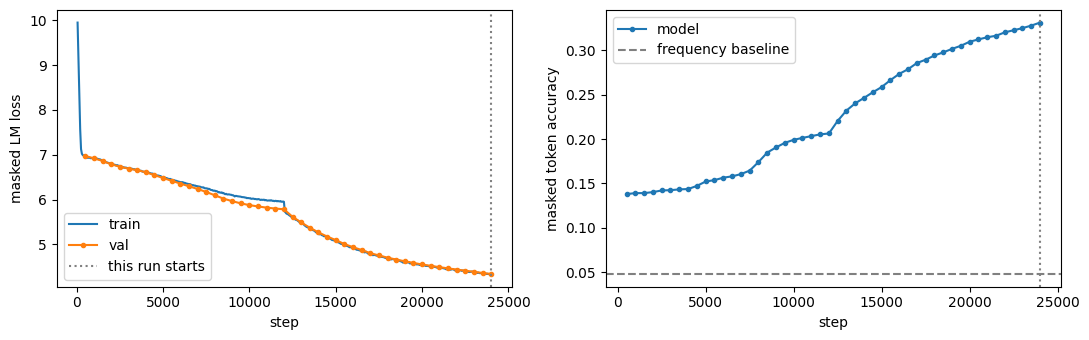

In [25]:
ck = torch.load("/kaggle/input/datasets/gbalachandhiran/best-model/best.pt_20261020_113549", map_location=device)
best_model = build_model(); best_model.load_state_dict(ck["model"])
full_val = val_chunks(val_ids, L)
vl, va = evaluate(best_model, full_val, CFG["micro_bs"])
print(f"best.pt (step {ck['step']}): full-validation loss {vl:.4f} | masked acc {va:.2%} | frequency baseline {BASELINE_ACC:.2%}")

@torch.no_grad()
def fill_mask(m, sentence, k=10):
    # Write masks as [MASK]. WikiText style: spaces around punctuation.
    m.eval()
    parts = sentence.split("[MASK]")
    ids, positions = [CLS], []
    for i, part in enumerate(parts):
        ids += fast.line_ids(part)
        if i < len(parts) - 1:
            positions.append(len(ids)); ids.append(MASK)
    ids.append(SEP)
    logits = m(torch.tensor([ids], device=device))[0]
    print(sentence)
    for pos in positions:
        lg = logits[pos].float(); lg[:N_SPECIAL] = float("-inf")
        top = torch.topk(lg.softmax(-1), k)
        print("   ", ", ".join(f"{bpe.id2tok[i.item()].replace('</w>', '')} ({p:.2f})" for p, i in zip(top.values, top.indices)))

for s in ["The capital of France is [MASK] .",
          "He was born in [MASK] in 1950 .",
          "The [MASK] won the match by two goals .",
          "The river flows into the [MASK] sea .",
         "Java is [MASK] language",
         "football is a sport and [MASK]",
         "programming is [MASK]"]:
    fill_mask(best_model, s)

import matplotlib.pyplot as plt
tr = [h for h in history if "train_loss" in h]; va_ = [h for h in history if "val_loss" in h]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot([h["step"] for h in tr], [h["train_loss"] for h in tr], label="train")
ax[0].plot([h["step"] for h in va_], [h["val_loss"] for h in va_], label="val", marker="o", ms=3)
ax[0].axvline(base_step, color="gray", ls=":", label="this run starts")
ax[0].set_xlabel("step"); ax[0].set_ylabel("masked LM loss"); ax[0].legend()
ax[1].plot([h["step"] for h in va_], [h["val_acc"] for h in va_], marker="o", ms=3, label="model")
ax[1].axhline(BASELINE_ACC, color="gray", ls="--", label="frequency baseline")
ax[1].axvline(base_step, color="gray", ls=":")
ax[1].set_xlabel("step"); ax[1].set_ylabel("masked token accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

In [8]:
!ls -lt /kaggle/working/yak/ckpt | head -n 10

total 109488
-rw-rw-rw- 1 root root 56054943 Oct 20 07:26 last.pt
-rw-rw-rw- 1 root root 56054943 Oct 20 07:19 best.pt
